# Backlog v1 — span 001 evidence

E00 and pilots H01/H04/H09/H11, fixed grouped partitions and a predeclared budget.
This notebook reads aggregate artifacts only. Its tables reflect available evidence,
including incomplete/failed runs. See docs/SPAN_001_PROTOCOL.md for controls and
docs/SPAN_001_RESULTS.md for the current outcome. No new official score is inferred.


In [1]:
import json, os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
repo=Path.cwd()
if repo.name=='notebooks':repo=repo.parent
directory=repo/'results/span_001'
plan=json.loads((directory/'span_plan.json').read_text())
display(pd.Series(plan,name='predeclared span plan').to_frame())
inventory=json.loads((directory/'artifact_inventory.json').read_text())
display(pd.Series(inventory,name='artifact inventory').to_frame())


,predeclared span plan
span,1
started_at,2026-11-03T10:06:28+00:00
deadline,2026-11-05T10:06:28+00:00
gpu_session_seconds_cap,43200
quota_used_at_start,40562.245
quota_reserved_at_start,0.0
focus,"[E00, H01, H09, H04, H11]"
seed,20261118
dev_rows,1024
feature_fit_rows,4096


,artifact inventory
split_ids_sha256,066f7ab82a3f14464ce0ef67bfd8b8b34ed190679bfea5...
sample_ids_sha256,716c065f583d45ef6028034e77349cf245b849abbf3f6d...
selection_sha256,68a097c19cabe454c99925cc41153fd9cfb4b5a35bc3f6...
baseline_predictions_sha256,5b2522d2be7fed1d490ebe6135afe97fe3863339d8c34a...
baseline_adapter_expected_sha256,8afc09d728698c7bcd02e47f9d427166b4b07b3644c848...
baseline_adapter_local_present,True
baseline_adapter_local_sha256,8afc09d728698c7bcd02e47f9d427166b4b07b3644c848...
baseline_kernel,arseniytrushin/llm-preference-qwen3-4b-train-002
baseline_kernel_version,1
baseline_temperature,0.72206


The exact sample IDs are private heavy artifacts, with their digest recorded
above. All fit rows are original training rows; the 1,024 evaluation rows are in the
existing development partition. They are exploratory because the project previously
inspected this data. No confirmation labels are evaluated for this span.


In [2]:
reports={name:json.loads(path.read_text()) for name in ('reward','joint')
         if (path:=directory/(name+'_results.json')).exists()}
if reports:
    reference=next(iter(reports.values()))
    display(pd.DataFrame([{'reference':'Frozen deployment temperature',**reference['baseline_deployed']},
                          {'reference':'Matched group-cross-fitted temperature',**reference['baseline_crossfit_temperature']}])
            [['reference','rows','log_loss','accuracy','tie_auc']])
rows=[]
for stage,report in reports.items():
    for item in report['models']:
        gain=item['gain_vs_deployed']
        rows.append({'stage':stage,'model':item['name'],
                     'raw_loss':item['raw']['log_loss'],
                     'crossfit_calibrated_loss':item['crossfit_temperature']['log_loss'],
                     'accuracy':item['crossfit_temperature']['accuracy'],
                     'tie_auc':item['crossfit_temperature']['tie_auc'],
                     'tie_recall':item['crossfit_temperature']['class_recall'][2],
                     'gain_vs_deployed':gain['gain'],'gain_interval_low':gain['interval_95'][0],
                     'gain_interval_high':gain['interval_95'][1],
                     'gain_vs_matched_crossfit':item['gain_vs_crossfit_baseline']['gain']})
table=pd.DataFrame(rows)
if len(table):display(table.round(6))
else:print('Model quality measurements are not available yet; preparation and live observations follow.')


,reference,rows,log_loss,accuracy,tie_auc
0,Frozen deployment temperature,1024,0.976350,0.522461,0.659566
1,Matched group-cross-fitted temperature,1024,0.977521,0.522461,0.659244


,stage,model,raw_loss,crossfit_calibrated_loss,accuracy,tie_auc,tie_recall,gain_vs_deployed,gain_interval_low,gain_interval_high,gain_vs_matched_crossfit
0,reward,reward_coupled,1.011246,1.015571,0.506836,0.593023,0.356037,-0.039221,-0.068212,-0.011427,-0.03805


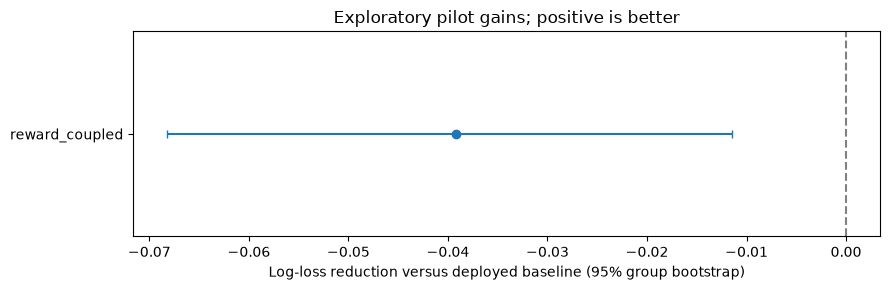

In [3]:
if len(table):
    fig,ax=plt.subplots(figsize=(9,max(3,len(table)*.45)))
    positions=np.arange(len(table))
    low=table.gain_vs_deployed-table.gain_interval_low
    high=table.gain_interval_high-table.gain_vs_deployed
    ax.errorbar(table.gain_vs_deployed,positions,xerr=np.vstack([low,high]),fmt='o',capsize=3)
    ax.axvline(0,color='gray',linestyle='--')
    ax.set(yticks=positions,yticklabels=table.model,xlabel='Log-loss reduction versus deployed baseline (95% group bootstrap)',
           title='Exploratory pilot gains; positive is better')
    ax.invert_yaxis();fig.tight_layout()
    figures=Path(os.environ.get('ARENA_DATA_DIR',str(Path.home()/'database/llm_classification_finetuning')))/'runs/span_001/figures'
    figures.mkdir(parents=True,exist_ok=True)
    fig.savefig(figures/'pilot_gains.png',dpi=180,bbox_inches='tight')
    fig.savefig(figures/'pilot_gains.svg',bbox_inches='tight')
    plt.show()


In [4]:
if 'joint' in reports:
    display(pd.DataFrame(reports['joint'].get('primary_comparisons',{})).T)
    for model in reports['joint']['models']:
        if model.get('raw_order'):
            print(model['name'],model['raw_order'])
    print('Frozen baseline reproduction:',reports['joint'].get('frozen_baseline_reproduction'))
if (directory/'reward_diagnostics.json').exists():
    print('H01 descriptive winner/tie decomposition; no hybrid was evaluated:')
    display(pd.Series(json.loads((directory/'reward_diagnostics.json').read_text())).to_frame())


H01 descriptive winner/tie decomposition; no hybrid was evaluated:


,0
decisive_rows,701
baseline_conditional_winner_accuracy,0.697575
reward_conditional_winner_accuracy,0.696148
conditional_winner_gain,"{'gain': -0.012320358743885767, 'interval_95':..."
interpretation,Descriptive decomposition of the declared H01 ...
head_direction_weight,1.045112


Head regularization and representation fitting use training-only grouped inner
folds. New probability calibration is cross-fitted by development prompt group.
The JSON records a matched cross-fitted baseline as well as the historically fitted
deployment baseline. Backbones can have unknown public-data exposure; our original
frozen classifier saw its full original training partition, so head-selection inner
folds are not independent backbone OOF experiments. Report all contrasts and avoid
interpreting these intervals as proof of untouched generalization.


In [5]:
jobs=[]
for path in sorted((directory/'jobs').glob('*/controller_state.json')):
    state=json.loads(path.read_text())
    intent_path=path.parent/'push_intent.json'
    intent=json.loads(intent_path.read_text()) if intent_path.exists() else {}
    quota_path=path.parent/'quota.json'
    quota=json.loads(quota_path.read_text()) if quota_path.exists() else {}
    jobs.append({'job':path.parent.name,'observed_stage':state.get('stage'),
                 'observed_status':state.get('status'),'snapshot_utc':state.get('utc'),
                 'version':state.get('version'),'session_ceiling_seconds':intent.get('max_session_seconds'),
                 'quota_used_snapshot':quota.get('used_seconds')})
display(pd.DataFrame(jobs))
print('These are dated observations, not a new live job query.')
if jobs:
    charges=[x['quota_used_snapshot'] for x in jobs if x['quota_used_snapshot'] is not None]
    if charges:print('Charged quota increase at latest snapshot:',max(charges)-plan['quota_used_at_start'],'seconds; unfinished use may not be posted yet.')
display(json.loads((directory/'preflight.json').read_text()))


,job,observed_stage,observed_status,snapshot_utc,version,session_ceiling_seconds,quota_used_snapshot
0,joint,waiting_for_kernel,RUNNING,2026-11-03T11:19:51.193832+00:00,1,25200,41721.459
1,reward,failed,ERROR,2026-11-03T10:33:21.796755+00:00,1,10800,40733.075
2,reward-tokenfix,complete,NaN,2026-11-03T10:54:59.794731+00:00,2,10800,41721.459


These are dated observations, not a new live job query.
Charged quota increase at latest snapshot: 1159.214 seconds; unfinished use may not be posted yet.


{'official_tokenizer_revision': 'fd958fef475f323f4e6b195930e3dd918485c668',
 'local_real_tokenizer_rows_verified': 5120,
 'max_packed_length': 988,
 'span_pack_sha256': '36be0e80d52dd6d4f47b9895b91527d0321fee06a1735e6bcf9a62af30710d34',
 'first_gpu_job': {'job': 'reward',
  'version': 1,
  'status': 'ERROR',
  'quota_seconds': 170.83,
  'cause': 'Chat-template BatchEncoding return was passed as a token list'},
 'recovery': 'Explicit flat-token extraction; same fixed rows/content policy; regression test and real tokenizer verification before retry'}

A finished pilot can have a negative or inconclusive result. Completing this
span requires evidence for every focus decision, executed results, a preserved v1
final snapshot and a v2 handoff. Newly discovered tasks enter v2; unfinished tasks
carry forward with their original IDs. Raw text and heavy artifacts stay outside Git.
